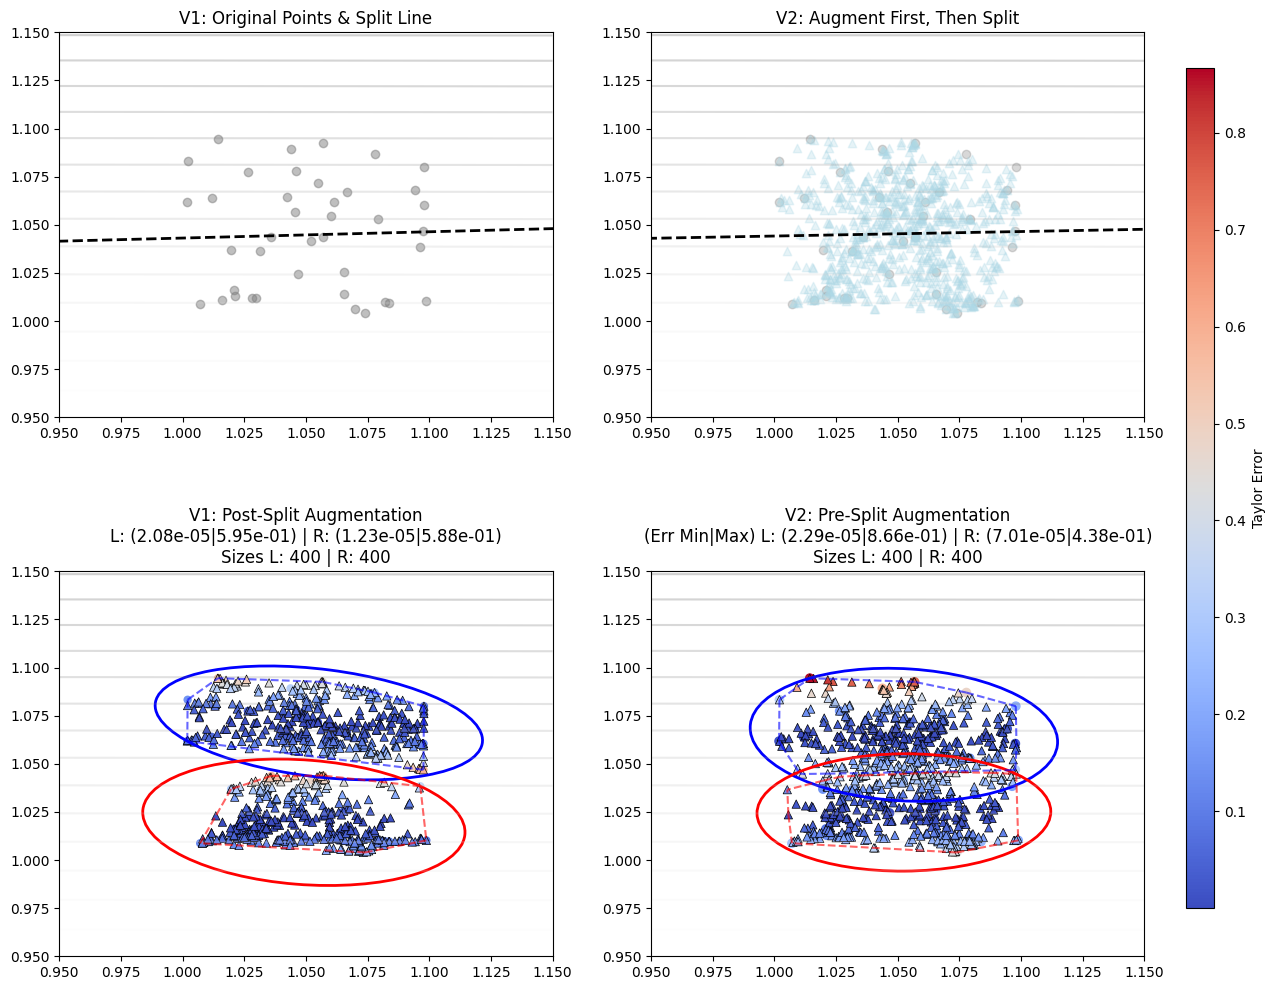

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse
from scipy.spatial import ConvexHull

# ---------------------------------------------------------
# 1. Setup & Mathematical Definitions (SymPy)
# ---------------------------------------------------------
np.random.seed(0)

x_sym, y_sym = sp.symbols("x y")
# Function with high curvature and interaction
f_sym = x_sym**2 + 1000 * y_sym**2 + 0 * x_sym * y_sym

f_np = sp.lambdify((x_sym, y_sym), f_sym, "numpy")


def f(X):
    return f_np(X[:, 0], X[:, 1])


grad_sym = [sp.diff(f_sym, var) for var in (x_sym, y_sym)]
grad_np = sp.lambdify((x_sym, y_sym), grad_sym, "numpy")
H_sym = sp.hessian(f_sym, (x_sym, y_sym))
H_np = sp.lambdify((x_sym, y_sym), H_sym, "numpy")


def surrogate_error(X, mu):
    if len(X) == 0:
        return np.array([])
    F_true = f(X)
    grad_val = np.array(grad_np(mu[0], mu[1])).flatten()
    F_surrogate = f(np.array([mu]))[0] + np.dot(X - mu, grad_val)
    return np.abs(F_true - F_surrogate)


def augment_points(X, num_synth):
    if num_synth <= 0:
        return np.empty((0, 2))
    idx1 = np.random.choice(len(X), num_synth)
    idx2 = np.random.choice(len(X), num_synth)
    t = np.random.rand(num_synth, 1)
    return t * X[idx1] + (1 - t) * X[idx2]


def hess_pca_median_split(X):
    mu = np.mean(X, axis=0)
    H_val = np.array(H_np(mu[0], mu[1]), dtype=float)
    dx = X - mu
    M = (dx @ H_val) @ dx.T
    M = 0.5 * (M + M.T)
    evals, evecs = np.linalg.eigh(M)
    alpha = evecs[:, np.argmax(evals)]
    pc = dx.T @ alpha
    pc /= np.linalg.norm(pc)
    scores = np.dot(dx, pc)
    mask_left = scores <= np.median(scores)
    return mask_left, ~mask_left, mu, pc, np.median(scores)


def draw_hull(ax, X, color):
    if len(X) >= 3:
        try:
            hull = ConvexHull(X)
            for simplex in hull.simplices:
                ax.plot(
                    X[simplex, 0], X[simplex, 1], "--", color=color, lw=1.5, alpha=0.6
                )
        except:
            pass


def draw_trust_ellipse(ax, X, color):
    if len(X) < 3:
        return
    mu = np.mean(X, axis=0)
    dx = X - mu
    cov = np.cov(dx, rowvar=False) + np.eye(2) * 1e-6
    vals, vecs = np.linalg.eigh(cov)
    inv_cov = np.linalg.inv(cov)
    dists = np.sum((dx @ inv_cov) * dx, axis=1)
    scale = np.sqrt(np.max(dists))
    width, height = 2 * scale * np.sqrt(vals)
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    ellipse = Ellipse(
        xy=mu,
        width=width,
        height=height,
        angle=angle,
        edgecolor=color,
        facecolor="none",
        lw=2,
        linestyle="-",
    )
    ax.add_patch(ellipse)


# ---------------------------------------------------------
# 2. Generate Base Data
# ---------------------------------------------------------
N, MIN_SZ = 40, 400
X_orig = np.random.uniform(1, 1.1, (N, 2))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
plt.subplots_adjust(hspace=0.4, wspace=0.2)

PROB_DOMAIN = (0.95, 1.15)
xx, yy = np.meshgrid(
    np.linspace(PROB_DOMAIN[0], PROB_DOMAIN[1], 100),
    np.linspace(PROB_DOMAIN[0], PROB_DOMAIN[1], 100),
)
Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

for ax in axes.flatten():
    ax.contour(xx, yy, Z, levels=15, cmap="Greys", alpha=0.2)
    ax.set_xlim(PROB_DOMAIN[0], PROB_DOMAIN[1])
    ax.set_ylim(PROB_DOMAIN[0], PROB_DOMAIN[1])

# ---------------------------------------------------------
# 3. Version 1: Split First, Augment Later
# ---------------------------------------------------------
ax1, ax2, ax3, ax4 = axes.flatten()
mL1, mR1, mu1, pc1, med1 = hess_pca_median_split(X_orig)
X_L1, X_R1 = X_orig[mL1], X_orig[mR1]

ax1.set_title("V1: Original Points & Split Line")
ax1.scatter(X_orig[:, 0], X_orig[:, 1], c="gray", alpha=0.5)
ortho1 = np.array([-pc1[1], pc1[0]])
line1 = mu1 + pc1 * med1 + np.outer(np.linspace(-5, 5, 10), ortho1)
ax1.plot(line1[:, 0], line1[:, 1], "k--", lw=2)

# Augment
XL_s1 = augment_points(X_L1, MIN_SZ - len(X_L1))
XR_s1 = augment_points(X_R1, MIN_SZ - len(X_R1))
XL_full1, XR_full1 = np.vstack([X_L1, XL_s1]), np.vstack([X_R1, XR_s1])

# Calculate Errors
mu_L1, mu_R1 = np.mean(XL_full1, axis=0), np.mean(XR_full1, axis=0)
eL1_orig = surrogate_error(X_L1, mu_L1)
eL1_synth = surrogate_error(XL_s1, mu_L1)
eR1_orig = surrogate_error(X_R1, mu_R1)
eR1_synth = surrogate_error(XR_s1, mu_R1)

eL1_all = np.concatenate([eL1_orig, eL1_synth])
eR1_all = np.concatenate([eR1_orig, eR1_synth])

# ---------------------------------------------------------
# 4. Version 2: Augment First, Then Split
# ---------------------------------------------------------
X_s2 = augment_points(X_orig, 2 * MIN_SZ - len(X_orig))
X_tot2 = np.vstack([X_orig, X_s2])
mL2, mR2, mu2, pc2, med2 = hess_pca_median_split(X_tot2)
XL_f2, XR_f2 = X_tot2[mL2], X_tot2[mR2]

ax2.set_title("V2: Augment First, Then Split")
ax2.scatter(X_orig[:, 0], X_orig[:, 1], c="gray", alpha=0.3)
ax2.scatter(X_s2[:, 0], X_s2[:, 1], c="lightblue", marker="^", alpha=0.3)
ortho2 = np.array([-pc2[1], pc2[0]])
line2 = mu2 + pc2 * med2 + np.outer(np.linspace(-5, 5, 10), ortho2)
ax2.plot(line2[:, 0], line2[:, 1], "k--", lw=2)

# Calculate Errors
eL2_all = surrogate_error(XL_f2, np.mean(XL_f2, axis=0))
eR2_all = surrogate_error(XR_f2, np.mean(XR_f2, axis=0))

# ---------------------------------------------------------
# Normalization & Plotting
# ---------------------------------------------------------
all_e = np.concatenate([eL1_all, eR1_all, eL2_all, eR2_all])
norm = LogNorm(vmin=max(all_e.min(), 1e-6), vmax=all_e.max())
norm = plt.Normalize(vmin=all_e.min(), vmax=all_e.max())

# V1 Errors Plot (ax3)
ax3.scatter(
    X_L1[:, 0], X_L1[:, 1], c=eL1_orig, cmap="coolwarm", norm=norm, edgecolors="none"
)
ax3.scatter(
    XL_s1[:, 0],
    XL_s1[:, 1],
    c=eL1_synth,
    cmap="coolwarm",
    norm=norm,
    marker="^",
    edgecolors="k",
    lw=0.5,
)
ax3.scatter(
    X_R1[:, 0], X_R1[:, 1], c=eR1_orig, cmap="coolwarm", norm=norm, edgecolors="none"
)
ax3.scatter(
    XR_s1[:, 0],
    XR_s1[:, 1],
    c=eR1_synth,
    cmap="coolwarm",
    norm=norm,
    marker="^",
    edgecolors="k",
    lw=0.5,
)
draw_hull(ax3, XL_full1, "blue")
draw_hull(ax3, XR_full1, "red")
draw_trust_ellipse(ax3, XL_full1, "blue")
draw_trust_ellipse(ax3, XR_full1, "red")

ax3.set_title(
    f"V1: Post-Split Augmentation\n"
    f"L: ({eL1_all.min():.2e}|{eL1_all.max():.2e}) | R: ({eR1_all.min():.2e}|{eR1_all.max():.2e})\n"
    f"Sizes L: {len(XL_full1)} | R: {len(XR_full1)}"
)

# V2 Errors Plot (ax4)
is_oL2 = mL2[:N]
is_sL2 = mL2[N:]
is_oR2 = mR2[:N]
is_sR2 = mR2[N:]

ax4.scatter(
    X_orig[is_oL2, 0],
    X_orig[is_oL2, 1],
    c=eL2_all[: sum(is_oL2)],
    cmap="coolwarm",
    norm=norm,
)
ax4.scatter(
    X_s2[is_sL2, 0],
    X_s2[is_sL2, 1],
    c=eL2_all[sum(is_oL2) :],
    cmap="coolwarm",
    norm=norm,
    marker="^",
    edgecolors="k",
    lw=0.5,
)
ax4.scatter(
    X_orig[is_oR2, 0],
    X_orig[is_oR2, 1],
    c=eR2_all[: sum(is_oR2)],
    cmap="coolwarm",
    norm=norm,
)
ax4.scatter(
    X_s2[is_sR2, 0],
    X_s2[is_sR2, 1],
    c=eR2_all[sum(is_oR2) :],
    cmap="coolwarm",
    norm=norm,
    marker="^",
    edgecolors="k",
    lw=0.5,
)
draw_hull(ax4, XL_f2, "blue")
draw_hull(ax4, XR_f2, "red")
draw_trust_ellipse(ax4, XL_f2, "blue")
draw_trust_ellipse(ax4, XR_f2, "red")

ax4.set_title(
    f"V2: Pre-Split Augmentation\n"
    f"(Err Min|Max) L: ({eL2_all.min():.2e}|{eL2_all.max():.2e}) | R: ({eR2_all.min():.2e}|{eR2_all.max():.2e})\n"
    f"Sizes L: {len(XL_f2)} | R: {len(XR_f2)}"
)

cbar_ax = fig.add_axes([0.93, 0.15, 0.02, 0.7])
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap="coolwarm"), cax=cbar_ax, label="Taylor Error"
)

# plt.savefig("ellipse_comparison.png")
plt.show()